In [2]:
import seaborn as sb
import numpy as np
import random
import math
import pandas as pd
import matplotlib.pyplot as plt
import scipy as sc

In [ ]:
1. Пусть Xi ∼ Bern(θ), для H0 : θ = 1/2 и H1 : θ = θ1, где а) θ1 = 1/3, б) θ1 = 2/3. Рассмотрим кри-
терий {sum Xi > C}, n = 10. Построить графики вероятностей ошибки I рода, ошибки II рода и
мощности критерия в зависимости от C. Для какой из двух альтернатив осмысленно использовать
этот критерий?

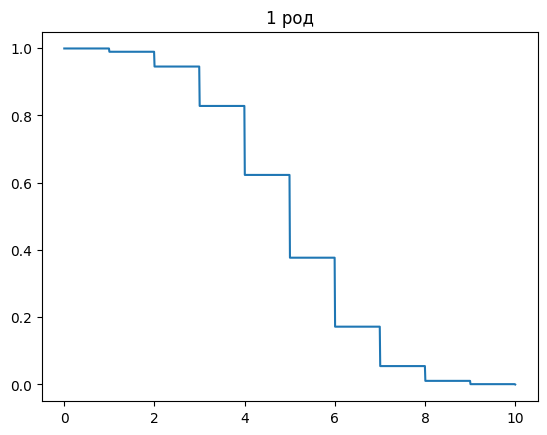

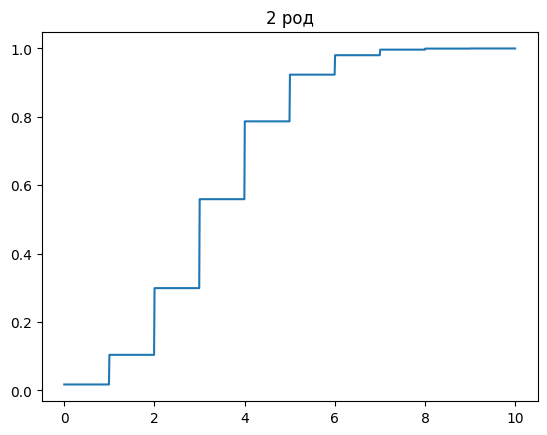

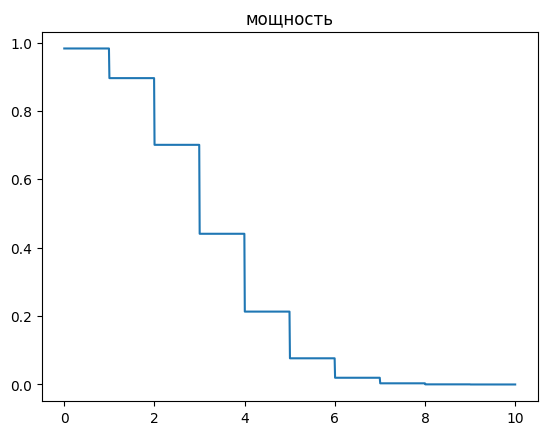

In [4]:
tetta0=1/2
tetta1=1/3
n=10
a=np.linspace(0,n,1000)
mis1=[1-sc.stats.binom.cdf(x, n, tetta0) for x in a]
mis2=[sc.stats.binom.cdf(x, n, tetta1) for x in a]
mosh=[1-sc.stats.binom.cdf(x, n, tetta1) for x in a]

plt.plot(a,mis1)
plt.title("1 род")
plt.show()
plt.plot(a,mis2)
plt.title("2 род")
plt.show()
plt.plot(a,mosh)
plt.title("мощность")
plt.show()

In [ ]:
пусть Xi ∼ N (θ, 1), H0 : θ = 0,
H1 : θ = θ1. Постройте а) критерий Неймана-Пирсона для θ1 > 0 б) для θ1 < 0 в) асимптотиче-
ский критерий |MED − x1/2| > C. Рассчитайте для них ф.р. статистик критерия, найдите p-value
критериев.

(a) Построить графики p-value всех трех критериев, выбирая данные а) при верной нулевой
гипотезе б) при каждой из альтернатив (θ1 = −1 и θ1 = 1). Построить их на одном графике.
В какую сторону отклоняются графики от прямой y = x?
(b) Как влияет размер выборки на отклонение от y = x?
(c) Какой критерий самый лучший?

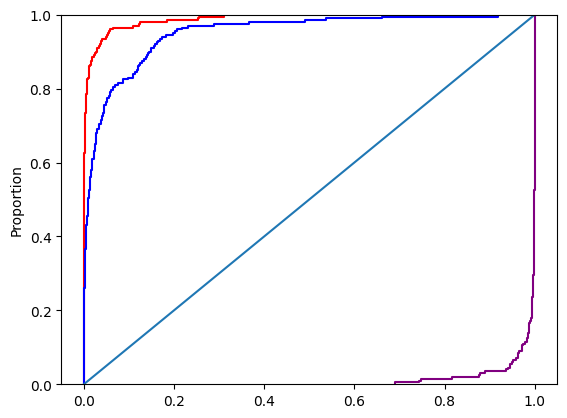

In [27]:
tetta=-1
n=10
m=200
p1=[0]*m
pminus1=[0]*m
pmed = [0]*m

for k in range(m):
    data=np.random.normal(loc=tetta,scale=1,size=n)
    p1[k]=1-sc.stats.norm.cdf(np.sum(data), loc = 0, scale = np.sqrt(n))
    pminus1[k]=sc.stats.norm.cdf(np.sum(data), loc = 0, scale = np.sqrt(n))
    pmed[k] =  2 - 2*sc.stats.norm.cdf(np.abs(np.median(data)), loc = 0, scale = np.sqrt(np.pi/ (2*n)) )
sb.ecdfplot(p1, color = "purple") #tetta=1
sb.ecdfplot(pminus1, color = "red")
sb.ecdfplot(pmed, color = "blue")
l=np.linspace(0,1,100)
plt.plot(l,l)
plt.show()

In [ ]:
3. X1, . . . , Xn ∼ Bern(θ), H0 : θ = 1/2, H1 : θ = 1/3. При каких n можно построить критическое мно-
жество вида {sum Xi < C} так, чтобы вероятности ошибок первого и второго рода не превышали
0.05? Построить графики вероятностей ошибок первого и второго рода (как функции от C) для
разных n.

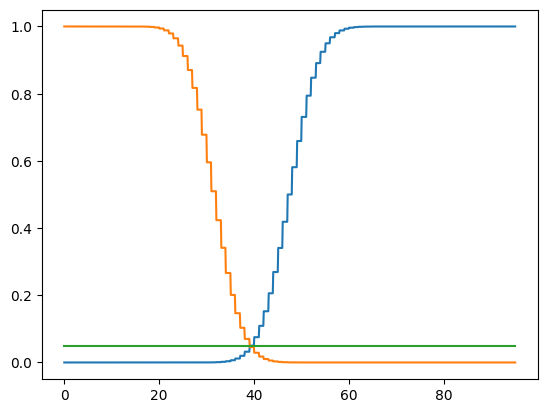

In [31]:
tetta0=1/2
tetta1=1/3
n=95
c=np.linspace(0,n,1000)
plt.plot(c, sc.stats.binom.cdf(c, n, tetta0))
plt.plot(c, 1-sc.stats.binom.cdf(c, n, tetta1))
plt.plot(c,[0.05]*1000)

In [ ]:
4. * Построить в предыдущей задаче рандомизированный критерий Неймана-Пирсона уровня значи-
мости 0.05. Эмпирически исследовать вероятность ошибки I рода критерия и убедиться, что она
действительно 0.05.
sum xi <2 

In [8]:
alpha=0.05
gamma=0.895
n=10
c=np.linspace(0,n,1000)
prob1=0
probg=0
m=10000
for k in range(m):
    data = np.random.binomial(1,0.5, size = n)
    if np.sum(data)<2:
        prob1+=1/m
    if np.sum(data)==2:
        probg+=1/m
print(prob1+gamma*probg)

0.05043300000000024
